# Лабораторна робота № 4
## Аналіз стійкості дискретних систем на z-площині та синтез цифрових КІХ/НІХ-фільтрів

**Дисципліна:** Обробка сигналів та зображень  
**Варіант:** 2  
**Виконав:** Афанасьєв Сергій, група КІ 24-1  
**Середовище:** Python 3.10+, NumPy, SciPy (`scipy.signal`), Matplotlib

## 1. Мета роботи

Дослідити зв'язок між розташуванням нулів і полюсів передавальної функції $H(z)$ та стійкістю дискретної системи, синтезувати цифрові фільтри верхніх частот — КІХ (метод вікон) та НІХ (Баттерворт, білінійне перетворення) — порівняти їхні частотні характеристики, груповий час затримки та якість придушення завади у зашумленому сигналі.

## 2. Основні співвідношення

- Передавальна функція системи з різницевим рівнянням $y[n] = \sum\limits_{k=0}^{M} b_k x[n-k] - \sum\limits_{k=1}^{K} a_k y[n-k]$:
$$H(z) = \frac{\sum\limits_{k=0}^{M} b_k z^{-k}}{1 + \sum\limits_{k=1}^{K} a_k z^{-k}} = k_0 \frac{\prod (z - z_i)}{\prod (z - p_i)}.$$
- Частотна характеристика — значення $H(z)$ на одиничному колі: $H(e^{j\omega}) = H(z)\big|_{z = e^{j\omega}}$, $\omega = 2\pi f / f_s$.
- BIBO-стійкість: система стійка тоді й лише тоді, коли $\sum |h[n]| < \infty$, що для каузальної системи рівносильно $|p_i| < 1$ для всіх полюсів (усі полюси всередині одиничного кола).
- Кут полюса $\theta = \arg p_i$ відповідає частоті резонансу $f = \theta f_s / 2\pi$, а його модуль визначає добротність: чим ближче $|p_i|$ до 1, тим гостріший резонанс. Нулі на одиничному колі дають нуль АЧХ.
- КІХ-фільтр: $H(z) = \sum\limits_{n=0}^{N-1} h[n] z^{-n}$ (усі полюси в нулі, тому він завжди стійкий). За симетричних коефіцієнтів $h[n] = h[N-1-n]$ фаза строго лінійна, а затримка $\tau = (N-1)/2$ відліків.
- Метод вікон: $h[n] = h_{ід}[n] \, w[n]$, де $h_{ід}$ — відлік ідеальної імпульсної характеристики (для ФВЧ: $\delta[n - \tau] - h_{ФНЧ}[n]$).
- НІХ-фільтр Баттерворта: $|H(j\Omega)|^2 = \dfrac{1}{1 + (\Omega/\Omega_c)^{2N}}$, максимально гладка АЧХ у смузі пропускання, на частоті зрізу $-3.01$ дБ. Білінійне перетворення $s = 2 f_s \dfrac{1 - z^{-1}}{1 + z^{-1}}$ відображає всю вісь $j\Omega$ на одиничне коло, при цьому $\Omega = 2 f_s \tan(\omega / 2)$ (потрібне попереднє викривлення частоти зрізу).
- Груповий час затримки $\tau_g(\omega) = -\dfrac{d \varphi(\omega)}{d \omega}$; для лінійної фази він постійний.
- Придушення завади: $D = 20 \lg \dfrac{A_{вх}}{A_{вих}}$, дБ.

## 3. Індивідуальне завдання (варіант 2)

Базова передавальна функція $H_{base}(z) = \dfrac{0.15 + 0.3 z^{-1} + 0.15 z^{-2}}{1 - 0.8 z^{-1} + 0.64 z^{-2}}$, тобто $[b_0, b_1, b_2, a_1, a_2] = [0.15; 0.3; 0.15; -0.8; 0.64]$.

| Тип фільтра | $f_s$, Гц | $f_c$, Гц | $N_{КІХ}$ | $N_{НІХ}$ | $A_1$, В | $f_1$, Гц | $A_2$, В | $f_2$, Гц | $\sigma$, В |
|---|---|---|---|---|---|---|---|---|---|
| ФВЧ | 1200 | 350 | 51 | 4 | 2.0 | 100 | 1.5 | 450 | 0.30 |

Аналітичний розрахунок:

- нулі: $0.15 (1 + z^{-1})^2$, тобто подвійний нуль $z = -1$ ($\omega = \pi$, частота Найквіста), $k_0 = 0.15$;
- полюси: $z^2 - 0.8 z + 0.64 = 0 \Rightarrow z = 0.4 \pm j\sqrt{0.64 - 0.16} = 0.4 \pm j\,0.6928$, $|p| = 0.8 < 1$, кут $60^\circ$ (резонанс на $60/360 \cdot 1200 = 200$ Гц) — система стійка;
- підсилення на постійній складовій: $H(1) = \dfrac{0.15 \cdot 4}{1 - 0.8 + 0.64} = \dfrac{0.6}{0.84} = 0.7143$;
- нестійкий аналог (мій вибір): ті самі $b$ та кут полюсів, але $a = [1; -1.2; 1.44]$, полюси $0.6 \pm j\,1.0392$, $|p| = 1.2 > 1$;
- нормована частота зрізу $f_c / (f_s / 2) = 350 / 600 = 0.5833$; затримка КІХ $(51 - 1) / 2 = 25$ відліків $= 20.83$ мс; для білінійного перетворення $\Omega_c = 2 f_s \tan(\pi f_c / f_s) = 2400 \cdot \tan 52.5^\circ \approx 3128$ рад/с;
- сигнал $x[n] = A_1 \sin(2\pi f_1 n / f_s) + A_2 \sin(2\pi f_2 n / f_s) + v[n]$. Для ФВЧ із $f_c = 350$ Гц складова $f_1 = 100$ Гц (нижче зрізу) — це низькочастотна завада, яку треба придушити, а $f_2 = 450$ Гц (вище зрізу) — корисний сигнал, який має зберегтися.

## 4. Хід виконання

Код розбито на блоки, повний скрипт знаходиться у файлі `lab4_filters_zplane.py`. Графіки зберігаються в каталог `figures/`.

### Блок 1. Імпорт бібліотек, налаштування стилю та функція побудови z-площини

In [1]:
import os
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq

# каталог для графіків
os.makedirs("figures", exist_ok=True)

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['grid.color'] = '#cccccc'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6


def plot_custom_zplane(b_coeffs, a_coeffs, ax, title_str):
    """Діаграма нулів (○) та полюсів (×) на z-площині з одиничним колом"""
    zeros, poles, gain = signal.tf2zpk(b_coeffs, a_coeffs)

    theta = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(theta), np.sin(theta), 'k--', lw=1.0, label='Одиничне коло')
    ax.axhline(0, color='gray', lw=0.8)
    ax.axvline(0, color='gray', lw=0.8)

    ax.plot(zeros.real, zeros.imag, 'o', color='g', mfc='none', ms=10, mew=2, label='Нулі')
    ax.plot(poles.real, poles.imag, 'x', color='r', ms=10, mew=2, label='Полюси')

    # кратні нулі підписуємо цифрою
    for z_val in np.unique(np.round(zeros, 6)):
        mult = int(np.sum(np.abs(zeros - z_val) < 1e-5))
        if mult > 1:
            ax.annotate(f"×{mult}", (z_val.real, z_val.imag), textcoords="offset points",
                        xytext=(8, 8), fontsize=11, color='g')

    ax.set_xlim(-1.8, 1.8)
    ax.set_ylim(-1.8, 1.8)
    ax.set_aspect('equal')
    ax.set_title(title_str)
    ax.set_xlabel("Re(z)")
    ax.set_ylabel("Im(z)")
    ax.grid(True)
    ax.legend(loc='upper left', fontsize=8)
    return zeros, poles

### Блок 2. Аналіз розташування полюсів та стійкості систем

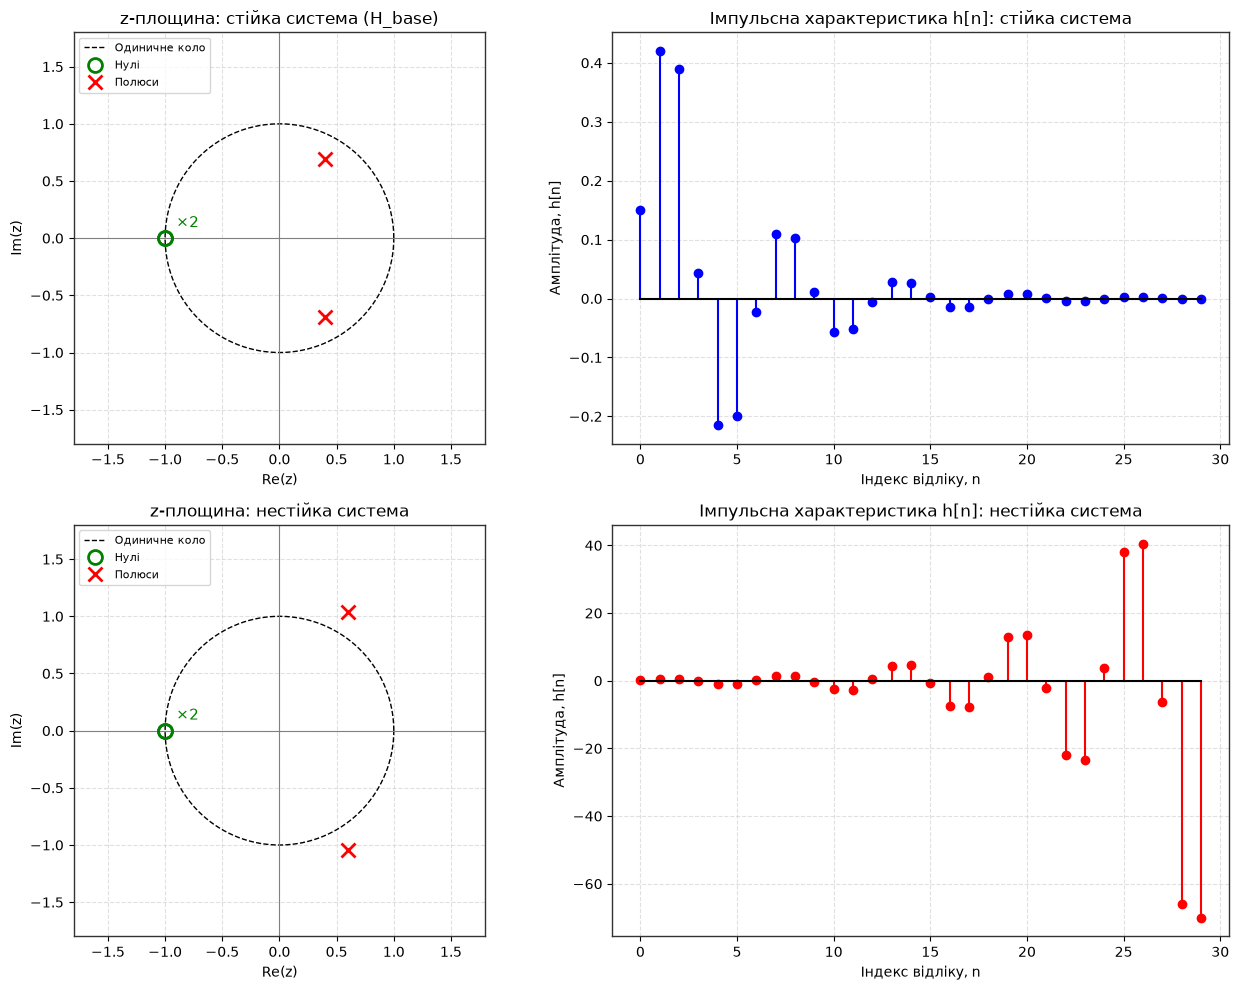

--- АНАЛІЗ РОЗТАШУВАННЯ ПОЛЮСІВ ТА СТІЙКОСТІ СИСТЕМ ---
Нулі H_base:  [-1. -1.] (кратність 2)
Підсилення k0 = 0.15; H(z=1) = 0.7143
Стійка система (H_base):
  полюси p = [0.4+0.6928j 0.4-0.6928j]
  модулі |p| = [0.8 0.8], кут = 60.0°
  стійка (усі |p| < 1): True
  h[29] = -9.430e-04, max|h[n]| = 4.200e-01
Нестійка система:
  полюси p = [0.6+1.0392j 0.6-1.0392j]
  модулі |p| = [1.2 1.2], кут = 60.0°
  стійка (усі |p| < 1): False
  h[29] = -7.006e+01, max|h[n]| = 7.006e+01


In [2]:
# базова передавальна функція варіанта 2: H_base(z) = (b0 + b1*z^-1 + b2*z^-2) / (1 + a1*z^-1 + a2*z^-2)
b_stable = [0.15, 0.3, 0.15]
a_stable = [1.0, -0.8, 0.64]

# для порівняння: той самий чисельник, полюси того ж кута, але з модулем 1.2 (за колом)
b_unstable = [0.15, 0.3, 0.15]
a_unstable = [1.0, -1.2, 1.44]

# імпульсні характеристики на 30 тактів
n_imp = np.arange(30)
delta_sig = np.zeros(30)
delta_sig[0] = 1.0
h_stable = signal.lfilter(b_stable, a_stable, delta_sig)
h_unstable = signal.lfilter(b_unstable, a_unstable, delta_sig)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
z_st, p_st = plot_custom_zplane(b_stable, a_stable, axes[0, 0], "z-площина: стійка система (H_base)")

axes[0, 1].stem(n_imp, h_stable, linefmt='b-', markerfmt='bo', basefmt='k-')
axes[0, 1].set_title("Імпульсна характеристика h[n]: стійка система")
axes[0, 1].set_xlabel("Індекс відліку, n")
axes[0, 1].set_ylabel("Амплітуда, h[n]")
axes[0, 1].grid(True)

z_un, p_unst = plot_custom_zplane(b_unstable, a_unstable, axes[1, 0], "z-площина: нестійка система")

axes[1, 1].stem(n_imp, h_unstable, linefmt='r-', markerfmt='ro', basefmt='k-')
axes[1, 1].set_title("Імпульсна характеристика h[n]: нестійка система")
axes[1, 1].set_xlabel("Індекс відліку, n")
axes[1, 1].set_ylabel("Амплітуда, h[n]")
axes[1, 1].grid(True)

plt.tight_layout()
plt.savefig("figures/zplane_stable_vs_unstable.png", dpi=300)
plt.show()

print("--- АНАЛІЗ РОЗТАШУВАННЯ ПОЛЮСІВ ТА СТІЙКОСТІ СИСТЕМ ---")
print(f"Нулі H_base:  {np.round(z_st, 4)} (кратність 2)")
print(f"Підсилення k0 = {signal.tf2zpk(b_stable, a_stable)[2]:.2f}; "
      f"H(z=1) = {np.sum(b_stable) / np.sum(a_stable):.4f}")
for name, p_vec, h_vec in (("Стійка система (H_base)", p_st, h_stable),
                           ("Нестійка система", p_unst, h_unstable)):
    print(f"{name}:")
    print(f"  полюси p = {np.round(p_vec, 4)}")
    print(f"  модулі |p| = {np.round(np.abs(p_vec), 4)}, кут = {np.degrees(np.angle(p_vec[0])):.1f}°")
    print(f"  стійка (усі |p| < 1): {np.all(np.abs(p_vec) < 1.0)}")
    print(f"  h[29] = {h_vec[29]:.3e}, max|h[n]| = {np.max(np.abs(h_vec)):.3e}")

**Результати аналізу стійкості:**

| Система | Полюси | $|p|$ | Кут | Стійка | $h[29]$ | $\max |h[n]|$ |
|---|---|---|---|---|---|---|
| Базова $H_{base}$ | $0.4 \pm j\,0.6928$ | 0.8 | 60° | так | $-9.43 \cdot 10^{-4}$ | 0.42 |
| Нестійка | $0.6 \pm j\,1.0392$ | 1.2 | 60° | ні | $-70.06$ | 70.06 |

Обидві системи мають однакові нулі (подвійний нуль у $z = -1$), однаковий кут полюсів ($60^\circ$, тобто 200 Гц), але різні модулі. У стійкої системи полюси всередині одиничного кола, імпульсна характеристика загасає за експонентним законом $0.8^n$ (на 30-му відліку $\approx 10^{-3}$ від максимуму). У нестійкої полюси поза колом, відгук зростає як $1.2^n$ і до 30-го відліку досягає 70, тобто у 167 разів перевищує максимум стійкої системи. На графіках z-площини видно, що в першому випадку пара полюсів лежить усередині кола, а в другому — поза ним.

### Блок 3. Синтез ФВЧ: КІХ (метод вікон) та НІХ (Баттерворт, білінійне перетворення)


--- СИНТЕЗ ФІЛЬТРІВ ВЕРХНІХ ЧАСТОТ ---
fs = 1200 Гц, f_c = 350 Гц, нормована частота зрізу = 0.5833
КІХ: 51 коефіцієнтів, вікно Хеммінга, затримка (N-1)/2 = 25 відліків
НІХ: Баттерворт 4-го порядку, b = [ 0.05299 -0.21195  0.31792 -0.21195  0.05299]
     a = [1.      0.65147 0.62047 0.14738 0.02617]
     модулі полюсів НІХ: [0.2385 0.2385 0.6784 0.6784], стійкий: True
|H(f_c)|: КІХ -6.10 дБ, НІХ -3.03 дБ
|H(100 Гц)|: КІХ -62.15 дБ, НІХ -54.89 дБ
|H(300 Гц)|: КІХ -54.85 дБ, НІХ -9.69 дБ
|H(450 Гц)|: КІХ -0.01 дБ, НІХ -0.03 дБ
Групова затримка: КІХ 25.00 відліків (стала на всіх частотах); НІХ у смузі пропускання від 1.70 до 3.84 відліків, на 450 Гц 2.34


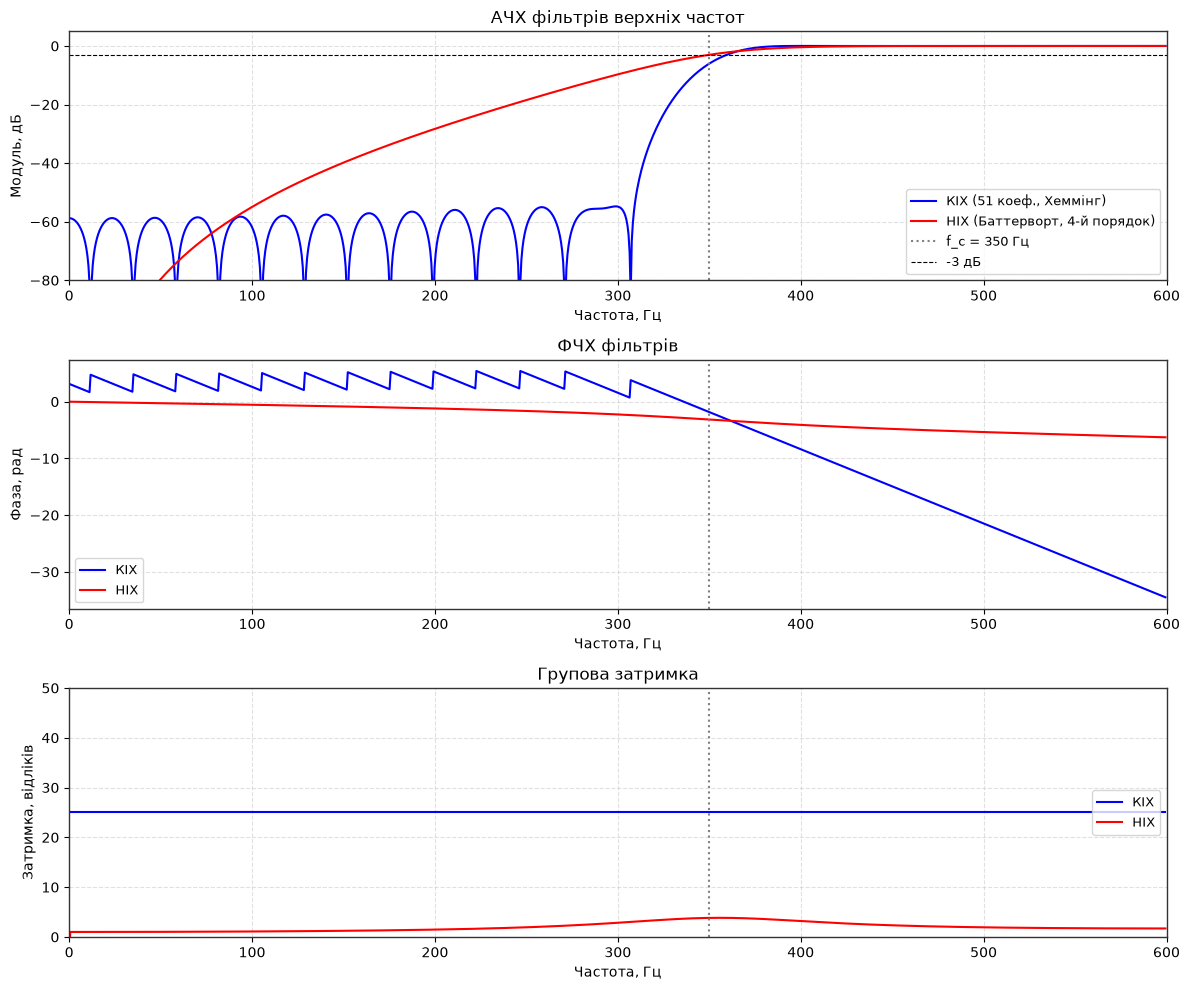

In [3]:
fs = 1200.0                      # частота дискретизації, Гц
f_cutoff = 350.0                 # частота зрізу, Гц
nyq_rate = fs / 2.0              # частота Найквіста, Гц
norm_cutoff = f_cutoff / nyq_rate

# КІХ-фільтр верхніх частот: усічена ідеальна характеристика, вікно Хеммінга
N_fir = 51
fir_coeffs = signal.firwin(N_fir, norm_cutoff, window='hamming', pass_zero=False)

# НІХ-фільтр верхніх частот Баттерворта 4-го порядку
N_iir = 4
b_iir, a_iir = signal.butter(N_iir, norm_cutoff, btype='high')

# частотні характеристики (1024 точки на інтервалі 0 ... fs/2)
w_fir, h_fir = signal.freqz(fir_coeffs, 1.0, worN=1024)
w_iir, h_iir = signal.freqz(b_iir, a_iir, worN=1024)
f_hz = w_fir * fs / (2 * np.pi)

# групова затримка, відліків (на ω = 0 у ФВЧ АЧХ дорівнює нулю, тому scipy попереджає про особливу точку)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    _, gd_fir = signal.group_delay((fir_coeffs, [1.0]), w=w_fir)
    _, gd_iir = signal.group_delay((b_iir, a_iir), w=w_iir)

poles_iir = np.roots(a_iir)
print("\n--- СИНТЕЗ ФІЛЬТРІВ ВЕРХНІХ ЧАСТОТ ---")
print(f"fs = {fs:.0f} Гц, f_c = {f_cutoff:.0f} Гц, нормована частота зрізу = {norm_cutoff:.4f}")
print(f"КІХ: {N_fir} коефіцієнтів, вікно Хеммінга, затримка (N-1)/2 = {(N_fir - 1) // 2} відліків")
print(f"НІХ: Баттерворт {N_iir}-го порядку, b = {np.round(b_iir, 5)}")
print(f"     a = {np.round(a_iir, 5)}")
print(f"     модулі полюсів НІХ: {np.round(np.sort(np.abs(poles_iir)), 4)}, "
      f"стійкий: {np.all(np.abs(poles_iir) < 1.0)}")
i_c = np.argmin(np.abs(f_hz - f_cutoff))
print(f"|H(f_c)|: КІХ {20 * np.log10(abs(h_fir[i_c])):.2f} дБ, НІХ {20 * np.log10(abs(h_iir[i_c])):.2f} дБ")
for f_probe in (100.0, 300.0, 450.0):
    i_p = np.argmin(np.abs(f_hz - f_probe))
    print(f"|H({f_probe:.0f} Гц)|: КІХ {20 * np.log10(abs(h_fir[i_p])):.2f} дБ, "
          f"НІХ {20 * np.log10(abs(h_iir[i_p])):.2f} дБ")
band = f_hz >= f_cutoff
print(f"Групова затримка: КІХ {gd_fir[np.argmin(np.abs(f_hz - 450.0))]:.2f} відліків (стала на всіх частотах); "
      f"НІХ у смузі пропускання від {np.min(gd_iir[band]):.2f} до {np.max(gd_iir[band]):.2f} відліків, "
      f"на 450 Гц {gd_iir[np.argmin(np.abs(f_hz - 450.0))]:.2f}")

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(f_hz, 20 * np.log10(np.maximum(np.abs(h_fir), 1e-5)), 'b-', label=f'КІХ ({N_fir} коеф., Хеммінг)')
axes[0].plot(f_hz, 20 * np.log10(np.maximum(np.abs(h_iir), 1e-5)), 'r-', label=f'НІХ (Баттерворт, {N_iir}-й порядок)')
axes[0].axvline(f_cutoff, color='gray', ls=':', label=f'f_c = {f_cutoff:.0f} Гц')
axes[0].axhline(-3, color='k', ls='--', lw=0.8, label='-3 дБ')
axes[0].set_ylim(-80, 5)
axes[0].set_xlim(0, fs / 2)
axes[0].set_title("АЧХ фільтрів верхніх частот")
axes[0].set_xlabel("Частота, Гц")
axes[0].set_ylabel("Модуль, дБ")
axes[0].grid(True)
axes[0].legend(loc='lower right', fontsize=9)

axes[1].plot(f_hz, np.unwrap(np.angle(h_fir)), 'b-', label='КІХ')
axes[1].plot(f_hz, np.unwrap(np.angle(h_iir)), 'r-', label='НІХ')
axes[1].axvline(f_cutoff, color='gray', ls=':')
axes[1].set_xlim(0, fs / 2)
axes[1].set_title("ФЧХ фільтрів")
axes[1].set_xlabel("Частота, Гц")
axes[1].set_ylabel("Фаза, рад")
axes[1].grid(True)
axes[1].legend(loc='lower left', fontsize=9)

axes[2].plot(f_hz, gd_fir, 'b-', label='КІХ')
axes[2].plot(f_hz, gd_iir, 'r-', label='НІХ')
axes[2].axvline(f_cutoff, color='gray', ls=':')
axes[2].set_ylim(0, 50)
axes[2].set_xlim(0, fs / 2)
axes[2].set_title("Групова затримка")
axes[2].set_xlabel("Частота, Гц")
axes[2].set_ylabel("Затримка, відліків")
axes[2].grid(True)
axes[2].legend(loc='center right', fontsize=9)

plt.tight_layout()
plt.savefig("figures/filter_frequency_responses.png", dpi=300)
plt.show()

**Результати синтезу ФВЧ** ($f_c = 350$ Гц, нормована частота $0.5833$):

| Фільтр | Параметри | $\lvert H(f_c) \rvert$, дБ | $\lvert H(100)\rvert$, дБ | $\lvert H(300)\rvert$, дБ | $\lvert H(450)\rvert$, дБ | Групова затримка, відліків |
|---|---|---|---|---|---|---|
| КІХ | 51 коеф., вікно Хеммінга | −6.10 | −62.15 | −54.85 | −0.01 | 25.00 (стала) |
| НІХ | Баттерворт, 4-й порядок | −3.03 | −54.89 | −9.69 | −0.03 | 1.70…3.84 у смузі пропускання, 2.34 на 450 Гц |

Коефіцієнти НІХ: $b = [0.05299; -0.21195; 0.31792; -0.21195; 0.05299]$, $a = [1; 0.65147; 0.62047; 0.14738; 0.02617]$; модулі полюсів $0.2385$ (×2) та $0.6784$ (×2) — фільтр стійкий.

Метод вікон дає для КІХ рівень $-6.10$ дБ на частоті зрізу (вікно Хеммінга ділить перехідну смугу навпіл по амплітуді 0.5), тоді як Баттерворт — $-3.03$ дБ (теоретичне значення $-3.01$ дБ). Спад КІХ значно крутіший: на 300 Гц (за 50 Гц нижче зрізу) він дає $-54.85$ дБ, а НІХ 4-го порядку — лише $-9.69$ дБ, бо 51 коефіцієнт із вікном Хеммінга формують глибоку смугу затримання. Групова затримка КІХ однакова на всіх частотах (25 відліків), у НІХ вона змінюється в смузі пропускання від 1.70 до 3.84 відліку, що спотворює форму сигналу.

### Блок 4. Фільтрація зашумленого сигналу та оцінка придушення завади


--- ОЦІНКА РЕЗУЛЬТАТІВ ФІЛЬТРАЦІЇ ---
Сигнал: 600 відліків, спектри на ділянці 432 відліків (df = 2.778 Гц); завада 100 Гц (2.0 В), корисна складова 450 Гц (1.5 В), шум sigma = 0.3 В
            A(100 Гц), В  A(450 Гц), В  придушення завади, дБ  збереження корисної, %
      Вхід        2.0189        1.5020                      -                       -
       КІХ        0.0020        1.5010                  60.02                   99.94
       НІХ        0.0029        1.5019                  56.84                  100.00
Фазовий зсув на 450 Гц: КІХ після компенсації затримки -0.000 рад, НІХ 1.481 рад (2.34 відліку групової затримки)


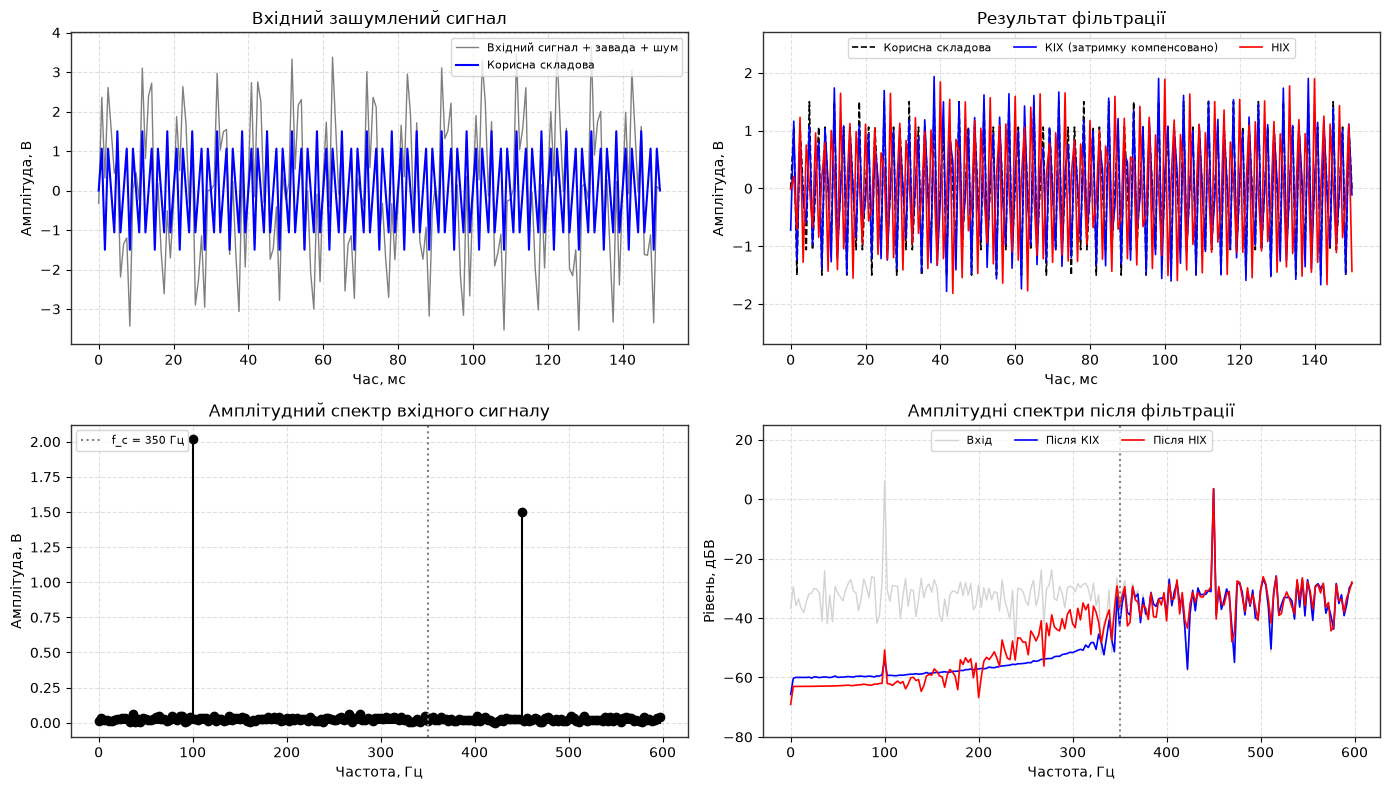


Моделювання завершено. Графіки збережено в 'figures/'.


In [4]:
# для ФВЧ корисна складова - високочастотна (f2 = 450 Гц), завада - низькочастотна (f1 = 100 Гц)
A1, f1 = 2.0, 100.0       # низькочастотна завада
A2, f2 = 1.5, 450.0       # корисний високочастотний сигнал
sigma = 0.30              # СКВ гаусового шуму, В

T_sig = 0.5
N_total = int(T_sig * fs)
t_sig = np.arange(N_total) / fs

np.random.seed(123)
s_clean = A2 * np.sin(2 * np.pi * f2 * t_sig)          # корисна складова
s_interf = A1 * np.sin(2 * np.pi * f1 * t_sig)         # завада
s_noise = np.random.normal(0.0, sigma, N_total)        # гаусів шум
s_input = s_clean + s_interf + s_noise

s_filtered_fir = signal.lfilter(fir_coeffs, 1.0, s_input)
s_filtered_iir = signal.lfilter(b_iir, a_iir, s_input)

# компенсація сталої затримки КІХ-фільтра
delay_fir = (N_fir - 1) // 2
s_filtered_fir_aligned = np.roll(s_filtered_fir, -delay_fir)


def get_magnitude_spectrum(data, rate):
    """Односторонній амплітудний спектр (В) та вісь частот (Гц)"""
    n_len = len(data)
    mag = 2.0 * np.abs(fft(data)[:n_len // 2]) / n_len
    mag[0] /= 2.0
    return fftfreq(n_len, 1.0 / rate)[:n_len // 2], mag


# спектри рахуємо на усталеній ділянці (після перехідних процесів фільтрів, поза "хвостом" np.roll)
# 432 відліки = 0.36 с: на ній вкладається рівно 36 періодів завади та 162 періоди корисного сигналу
n_start, n_seg = 120, 432
steady = slice(n_start, n_start + n_seg)

f_axis, mag_input = get_magnitude_spectrum(s_input[steady], fs)
_, mag_fir = get_magnitude_spectrum(s_filtered_fir_aligned[steady], fs)
_, mag_iir = get_magnitude_spectrum(s_filtered_iir[steady], fs)

i_f1 = int(np.argmin(np.abs(f_axis - f1)))
i_f2 = int(np.argmin(np.abs(f_axis - f2)))

print("\n--- ОЦІНКА РЕЗУЛЬТАТІВ ФІЛЬТРАЦІЇ ---")
print(f"Сигнал: {N_total} відліків, спектри на ділянці {n_seg} відліків (df = {fs / n_seg:.3f} Гц); "
      f"завада {f1:.0f} Гц ({A1} В), корисна складова {f2:.0f} Гц ({A2} В), шум sigma = {sigma} В")
print(f"{'':>10} {'A(100 Гц), В':>13} {'A(450 Гц), В':>13} {'придушення завади, дБ':>22} {'збереження корисної, %':>23}")
print(f"{'Вхід':>10} {mag_input[i_f1]:13.4f} {mag_input[i_f2]:13.4f} {'-':>22} {'-':>23}")
for name, mag in (("КІХ", mag_fir), ("НІХ", mag_iir)):
    sup_db = 20 * np.log10(mag_input[i_f1] / mag[i_f1])
    keep = 100.0 * mag[i_f2] / mag_input[i_f2]
    print(f"{name:>10} {mag[i_f1]:13.4f} {mag[i_f2]:13.4f} {sup_db:22.2f} {keep:23.2f}")

# фазовий зсув корисної складової після фільтра (КІХ - після компенсації затримки)
i_450 = int(np.argmin(np.abs(f_hz - f2)))
phase_fir = np.angle(h_fir[i_450] * np.exp(1j * w_fir[i_450] * delay_fir))
phase_iir = np.angle(h_iir[i_450])
print(f"Фазовий зсув на {f2:.0f} Гц: КІХ після компенсації затримки {phase_fir:.3f} рад, "
      f"НІХ {phase_iir:.3f} рад ({gd_iir[i_450]:.2f} відліку групової затримки)")

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
t_ms = t_sig * 1000
mask = t_ms <= 150

axes[0, 0].plot(t_ms[mask], s_input[mask], color='gray', lw=1.0, label='Вхідний сигнал + завада + шум')
axes[0, 0].plot(t_ms[mask], s_clean[mask], 'b-', lw=1.5, label='Корисна складова')
axes[0, 0].set_title("Вхідний зашумлений сигнал")
axes[0, 0].set_xlabel("Час, мс")
axes[0, 0].set_ylabel("Амплітуда, В")
axes[0, 0].grid(True)
axes[0, 0].legend(loc='upper right', fontsize=8)

axes[0, 1].plot(t_ms[mask], s_clean[mask], 'k--', lw=1.2, label='Корисна складова')
axes[0, 1].plot(t_ms[mask], s_filtered_fir_aligned[mask], 'b-', lw=1.2, label='КІХ (затримку компенсовано)')
axes[0, 1].plot(t_ms[mask], s_filtered_iir[mask], 'r-', lw=1.2, label='НІХ')
axes[0, 1].set_ylim(-2.7, 2.7)
axes[0, 1].set_title("Результат фільтрації")
axes[0, 1].set_xlabel("Час, мс")
axes[0, 1].set_ylabel("Амплітуда, В")
axes[0, 1].grid(True)
axes[0, 1].legend(loc='upper center', ncol=3, fontsize=8)

axes[1, 0].stem(f_axis, mag_input, linefmt='k-', markerfmt='ko', basefmt='k-')
axes[1, 0].axvline(f_cutoff, color='gray', ls=':', label=f'f_c = {f_cutoff:.0f} Гц')
axes[1, 0].set_title("Амплітудний спектр вхідного сигналу")
axes[1, 0].set_xlabel("Частота, Гц")
axes[1, 0].set_ylabel("Амплітуда, В")
axes[1, 0].grid(True)
axes[1, 0].legend(loc='upper left', fontsize=8)

axes[1, 1].plot(f_axis, 20 * np.log10(np.maximum(mag_input, 1e-6)), color='lightgray', lw=1.0, label='Вхід')
axes[1, 1].plot(f_axis, 20 * np.log10(np.maximum(mag_fir, 1e-6)), 'b-', lw=1.2, label='Після КІХ')
axes[1, 1].plot(f_axis, 20 * np.log10(np.maximum(mag_iir, 1e-6)), 'r-', lw=1.2, label='Після НІХ')
axes[1, 1].axvline(f_cutoff, color='gray', ls=':')
axes[1, 1].set_ylim(-80, 25)
axes[1, 1].set_title("Амплітудні спектри після фільтрації")
axes[1, 1].set_xlabel("Частота, Гц")
axes[1, 1].set_ylabel("Рівень, дБВ")
axes[1, 1].grid(True)
axes[1, 1].legend(loc='upper center', ncol=3, fontsize=8)

plt.tight_layout()
plt.savefig("figures/signal_filtering_results.png", dpi=300)
plt.show()

print("\nМоделювання завершено. Графіки збережено в 'figures/'.")

**Результати фільтрації** (600 відліків; спектри — на сталій ділянці з 432 відліків, $\Delta f = 2.778$ Гц, ціла кількість періодів обох гармонік):

| Сигнал | $A(100\ \text{Гц})$, В | $A(450\ \text{Гц})$, В | Придушення завади, дБ | Збереження корисної, % |
|---|---|---|---|---|
| Вхід | 2.0189 | 1.5020 | — | — |
| КІХ | 0.0020 | 1.5010 | 60.02 | 99.94 |
| НІХ | 0.0029 | 1.5019 | 56.84 | 100.00 |

Обидва фільтри практично повністю прибирають низькочастотну завальну складову 100 Гц (на 60.0 дБ — КІХ, на 56.8 дБ — НІХ) і зберігають корисну складову 450 Гц із похибкою менше 0.1 %. Відмінність між ними — у фазі. КІХ додає лінійну фазу, і після компенсації затримки (зсув на 25 відліків) фазовий зсув на 450 Гц дорівнює нулю, тому форма сигналу зберігається. НІХ має нелінійну ФЧХ: на 450 Гц зсув 1.481 рад (групова затримка 2.34 відліку), який простим зсувом сигналу не усувається. Завада на 100 Гц лежить далеко від зрізу, тому обидва фільтри її прибирають; близько до зрізу (300 Гц) відмінність суттєва, але КІХ вимагає 51 коефіцієнт проти 5 + 5 у НІХ, і щоб наблизити НІХ до такої крутизни, порядок Баттерворта довелося б збільшувати.

## 5. Висновки

1. Стійкість визначається модулями полюсів. Базова система варіанта 2 має полюси $0.4 \pm j\,0.6928$ з $|p| = 0.8 < 1$ і є стійкою: імпульсна характеристика загасає ($h[29] \approx -9.4 \cdot 10^{-4}$). Її нестійкий аналог зі збільшеним до 1.2 модулем полюсів за незмінного кута 60° має $|h[29]| = 70.06$ і зростає необмежено. Нулі (подвійний нуль $z = -1$) на стійкість не впливають.

2. Розташування полюса на куті 60° означає резонанс на 200 Гц; чим ближче полюси до одиничного кола, тим вужчий і вищий резонансний пік АЧХ.

3. КІХ-фільтр (51 коефіцієнт, вікно Хеммінга) завжди стійкий і має строго лінійну фазу з сталою затримкою 25 відліків. Він придушує заваду на 100 Гц на 62.2 дБ за АЧХ і на 60.0 дБ у зашумленому сигналі, зберігаючи 99.94 % амплітуди корисної складової 450 Гц.

4. НІХ-фільтр Баттерворта 4-го порядку (білінійне перетворення) для сигналу варіанта дає майже такий самий результат (придушення 56.8 дБ, збереження 100 %) лише з п'ятьма коефіцієнтами в чисельнику та знаменнику, хоча спад крутіший у КІХ (−54.85 проти −9.69 дБ на 300 Гц), має плоску АЧХ у смузі пропускання та $-3.03$ дБ на частоті зрізу. Ціна — нелінійна фаза (групова затримка 1.70…3.84 відліку в смузі пропускання, фазовий зсув 1.481 рад на 450 Гц) і необхідність перевіряти стійкість (усі полюси фільтра $|p| \le 0.6784$, тому він стійкий).

5. Вибір типу залежить від задачі: якщо важлива форма сигналу (вимірювальні, біомедичні сигнали), використовують КІХ із лінійною фазою; якщо важлива обчислювальна економність за заданої крутизни — НІХ.

## Відповідь на контрольні питання

**1. Що таке передавальна функція $H(z)$ дискретної системи, і як вона пов'язана з коефіцієнтами лінійного різницевого рівняння?**

* **Визначення:** Передавальна (системна) функція $H(z)$ лінійної стаціонарної дискретної системи — це відношення $z$-перетворення вихідного сигналу $Y(z)$ до $z$-перетворення вхідного сигналу $X(z)$ за нульових початкових умов, яке водночас є $z$-перетворенням імпульсної характеристики системи $h[n]$:

$$H(z) = \frac{Y(z)}{X(z)} = \sum_{n=-\infty}^{\infty} h[n] z^{-n}$$


* **Зв'язок із лінійним різницевим рівнянням:** Дискретна система зі сталими параметрами описується лінійним різницевим рівнянням:

$$\sum_{k=0}^{N} a_k y[n - k] = \sum_{m=0}^{M} b_m x[n - m]$$



Застосовуючи властивість зсуву $z$-перетворення ($\mathcal{Z}\{x[n-k]\} = z^{-k}X(z)$) при нульових початкових умовах, отримуємо раціональну функцію:

$$H(z) = \frac{Y(z)}{X(z)} = \frac{\sum_{m=0}^{M} b_m z^{-m}}{\sum_{k=0}^{N} a_k z^{-k}} = \frac{b_0 + b_1 z^{-1} + \dots + b_M z^{-M}}{a_0 + a_1 z^{-1} + \dots + a_N z^{-N}}$$



Таким чином, коефіцієнти прямої гілки $b_m$ (при відліках входу $x[n-m]$) безпосередньо визначають поліном чисельника (нулі системи), а коефіцієнти зворотного зв'язку $a_k$ (при відліках виходу $y[n-k]$) формують поліном знаменника (полюси системи).

---

**2. У чому полягає геометричний та алгебраїчний зміст критерію стійкості BIBO для лінійних стаціонарних дискретних систем у z-площині?**

Критерій BIBO (Bounded-Input, Bounded-Output) стверджує, що система є стійкою тоді й лише тоді, коли будь-який обмежений за амплітудою вхідний сигнал ($\vert{}x[n]\vert{} \le M_x < \infty$) породжує обмежений за амплітудою вихідний сигнал ($\vert{}y[n]\vert{} \le M_y < \infty$).

* **Алгебраїчний зміст:** У часовій області імпульсна характеристика системи має бути абсолютно сумовною:

$$\sum_{n=-\infty}^{\infty} \vert{}h[n]\vert{} < \infty$$



У $z$-області це еквівалентно тому, що область збіжності (ROC) передавальної функції $H(z)$ включає одиничне коло $\vert{}z\vert{} = 1$. Для каузальної раціональної системи модулі всіх полюсів $p_k$ (коренів знаменника $H(z)$) повинні бути строго меншими за одиницю:

$$\vert{}p_k\vert{} < 1 \quad \forall k$$


* **Геометричний зміст:** У комплексній $z$-площині **усі полюси передавальної функції каузальної системи повинні лежати строго всередині одиничного кола** ($\vert{}z\vert{} = 1$). Якщо хоча б один полюс розташований поза колом ($\vert{}p_k\vert{} > 1$) або на самому одиничному колі ($\vert{}p_k\vert{} = 1$), імпульсна характеристика не затухає або необмежено зростає, і система втрачає стійкість.

---

**3. Як впливає розташування нулів та полюсів передавальної функції відносно одиничного кола на форму амплітудно-частотної характеристики (АЧХ)?**

АЧХ системи визначається як значення модуля передавальної функції на одиничному колі $z = e^{j\omega}$, що геометрично дорівнює добутку відстаней від поточної точки частоти $e^{j\omega}$ до всіх нулів $z_m$, поділеному на добуток відстаней до всіх полюсів $p_k$:


$$\vert{}H(e^{j\omega})\vert{} = \vert{}K\vert{} \frac{\prod_{m=1}^{M} \vert{}e^{j\omega} - z_m\vert{}}{\prod_{k=1}^{N} \vert{}e^{j\omega} - p_k\vert{}}$$

* **Вплив полюсів ($p_k$):** Оскільки відстані до полюсів стоять у знаменнику, наближення полюса до одиничного кола на кутовій частоті $\omega_p$ різко зменшує знаменник при $\omega \approx \omega_p$ і створює **резонансний підйом (пік)** на АЧХ. Чим ближче полюс до межі $\vert{}z\vert{} = 1$, тим вищий і вужчий пік підсилення.
* **Вплив нулів ($z_m$):** Оскільки відстані до нулів стоять у чисельнику, наближення нуля до одиничного кола на кутовій частоті $\omega_z$ зменшує чисельник і формує **провал (ослаблення)** на АЧХ. Якщо нуль лежить безпосередньо на одиничному колі ($z_m = e^{j\omega_z}$), на частоті $\omega_z$ відстань дорівнює нулю, що забезпечує повне пригнічення сигналу ($\vert{}H(e^{j\omega_z})\vert{} = 0$, режекцію).
* **Віддалені особливості:** Нулі та полюси, розташовані поблизу початку координат ($z \approx 0$), знаходяться на майже однаковій відстані від усіх точок одиничного кола, тому впливають на форму АЧХ плавно й незначно.

---

**4. Чому всі цифрові КІХ-фільтри є безумовно стійкими, і за якої умови вони забезпечують строго лінійну фазочастотну характеристику?**

* **Причина безумовної стійкості:** КІХ-фільтр (фільтр зі скінченною імпульсною характеристикою) не має зворотних зв'язків ($a_0 = 1$, а всі $a_k = 0$ для $k \ge 1$). Його передавальна функція є поліномом від $z^{-1}$:

$$H(z) = \sum_{n=0}^{M} b_n z^{-n} = \frac{b_0 z^M + b_1 z^{M-1} + \dots + b_M}{z^M}$$



Усі полюси такої функції зосереджені в початку координат ($z = 0$), тобто лежать строго всередині одиничного кола ($\vert{}0\vert{} < 1$). Водночас імпульсна характеристика $h[n] = b_n$ має скінченну довжину та скінченні значення коефіцієнтів, тому умова $\sum_{n=0}^{M} \vert{}h[n]\vert{} < \infty$ виконується завжди.
* **Умова строго лінійної ФЧХ:** Імпульсна характеристика $h[n]$ порядку $M$ (довжиною $N = M + 1$) повинна бути **симетричною** або **антисиметричною** відносно свого центра:
* **Симетрія:** $h[n] = h[M - n]$ (типи I та II) — забезпечує чисто лінійну фазу $\varphi(\omega) = -\omega \frac{M}{2}$.
* **Антисиметрія:** $h[n] = -h[M - n]$ (типи III та IV) — забезпечує узагальнену лінійну фазу $\varphi(\omega) = \pm\frac{\pi}{2} - \omega \frac{M}{2}$.



---

**5. Які переваги та недоліки мають НІХ-фільтри у порівнянні з КІХ-фільтрами при однакових вимогах до крутизни спаду АЧХ у перехідній смузі?**

* **Переваги НІХ-фільтрів (з нескінченною імпульсною характеристикою):**
* **Значно нижчий порядок фільтра:** Для отримання однакової вузької перехідної смуги та крутого спаду АЧХ НІХ-фільтр потребує у кілька (або десятки) разів меншого порядку, ніж КІХ-фільтр.
* **Менша обчислювальна складність і витрати пам'яті:** Менше коефіцієнтів означає меншу кількість операцій множення-додавання на кожен відлік та меншу кількість елементів затримки.
* **Менша затримка поширення сигналу (latency):** Завдяки низькому порядку фільтр вносить значно меншу часову затримку, що важливо для систем реального часу та замкнених контурів керування.
* **Можливість синтезу за класичними аналоговими прототипами** (Баттерворта, Чебишева, Кауера).


* **Недоліки НІХ-фільтрів:**
* **Нелінійність ФЧХ:** Каузальні НІХ-фільтри не можуть забезпечити строго лінійну фазову характеристику (особливо поблизу частоти зрізу), через що вносять фазові спотворення у форму складних сигналів.
* **Ризик втрати стійкості та чутливість до квантування:** Наявність зворотних зв'язків може призвести до виходу полюсів за межі одиничного кола при округленні коефіцієнтів у арифметиці з фіксованою комою, а також до появи граничних циклів (паразитних автоколивань).



---

**6. Що таке груповий час затримки (Group Delay), і чому постійність цієї величини є критично важливою для передачі вимірювальних та біомедичних сигналів?**

* **Визначення групового часу затримки:** Груповий час затримки $\tau_g(\omega)$ характеризує часову затримку обвідної (або вузькосмугового хвильового пакета) на кожній частоті $\omega$ і визначається як від'ємна похідна фазочастотної характеристики $\varphi(\omega)$ за частотою:

$$\tau_g(\omega) = -\frac{d\varphi(\omega)}{d\omega}$$


* **Критична важливість постійності $\tau_g(\omega) = \text{const}$ для вимірювальних та біомедичних сигналів:**
* Складні імпульсні сигнали (ЕКГ, ЕЕГ, ЕМГ, сигнали датчиків) складаються з багатьох гармонік із жорсткими взаємними фазовими співвідношеннями. Якщо $\tau_g(\omega) = \text{const}$ (що відповідає лінійній ФЧХ $\varphi(\omega) = -\tau_g \omega$), **усі частотні компоненти затримуються фільтром на однаковий час**. Сигнал зсувається у часі без зміни своєї початкової форми.
* Якщо ж $\tau_g(\omega)$ змінюється з частотою (фазова дисперсія), різні гармоніки приходять на вихід із різною затримкою. У біомедичних і вимірювальних системах це викликає **спотворення морфології хвилі** — розмиття фронтів імпульсів, зміну пікових амплітуд, появу паразитних коливань або спотворення діагностично важливих інтервалів (наприклад, форми QRS-комплексу чи зміщення ST-сегмента на ЕКГ), що призводить до хибних вимірювань або неправильного діагнозу.



---

**7. У чому полягає суть методу білінійного z-перетворення (Тастіна), і чому воно вимагає попереднього спотворення частотної шкали (frequency pre-warping)?**

* **Суть методу білінійного $z$-перетворення (Тастіна):** Це алгебраїчний метод проєктування цифрового НІХ-фільтра $H(z)$ на основі передавальної функції аналогового прототипу $H_a(s)$ шляхом підстановки дробово-лінійного перетворення (еквівалентного чисельному інтегруванню за методом трапецій):

$$s = \frac{2}{T_s} \frac{1 - z^{-1}}{1 + z^{-1}} = \frac{2}{T_s} \frac{z - 1}{z + 1}$$



Це відображення взаємно однозначно переводить усю нескінченну уявну вісь аналогових частот $s = j\Omega$ ($\Omega \in (-\infty, +\infty)$) в одиничне коло цифрових частот $z = e^{j\omega}$ ($\omega \in (-\pi, \pi)$), що **повністю усуває накладання спектрів (аліасинг)** та гарантує перехід стійкого аналогового фільтра ($\text{Re}(s) < 0$) у стійкий цифровий ($\vert{}z\vert{} < 1$).
* **Необхідність попереднього спотворення частотної шкали (frequency pre-warping):** Підстановка $s = j\Omega$ та $z = e^{j\omega}$ у формулу Тастіна дає нелінійний зв'язок між аналоговою частотою $\Omega$ та цифровою частотою $\omega$:

$$\Omega = \frac{2}{T_s} \tan\left(\frac{\omega}{2}\right) \quad \Longleftrightarrow \quad \omega = 2 \arctan\left(\frac{\Omega T_s}{2}\right)$$



Через нелінійне стиснення частотної осі (warping) у високочастотній області граничні частоти (зрізу, смуги пропускання чи режекції) цифрового фільтра зміщуються відносно заданих. Щоб ключові частоти $\omega_c$ цифрового фільтра точно збігалися з вимогами технічного завдання, перед білінійною підстановкою частоти аналогового прототипу заздалегідь коригують (спотворюють) за формулою:

$$\Omega_c = \frac{2}{T_s} \tan\left(\frac{\omega_c}{2}\right)$$



Після виконання $z$-перетворення ці попередньо зміщені частоти точно повертаються у потрібні положення $\omega_c$.